### Case Study: **Jbel Saghro, Morocco**

*Primary to Intermediate - Alkaline*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/morocco/jbel_saghro.ipynb)

The Jbel Saghro Volcanic Field (JSVF) is located in the eastern Anti-Atlas of Morocco at the northern boundary of the West African Craton. They represent an alkaline suite of primary to intermediate compositions with nephelinites present. The liquid line of descent of the Jbel Saghro lavas can be modelled using fractional crystallisation.

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/morocco) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/morocco/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [1]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel(
    mode='alkaline'
)

# Load the data suite and use the auto-computed samples for the projected LLOD
model.load_data_suite('./jbel_saghro.xlsx')

hades-obol v0.8.4. This is a pre-release version. Check for updates using hades.check_for_updates()


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions

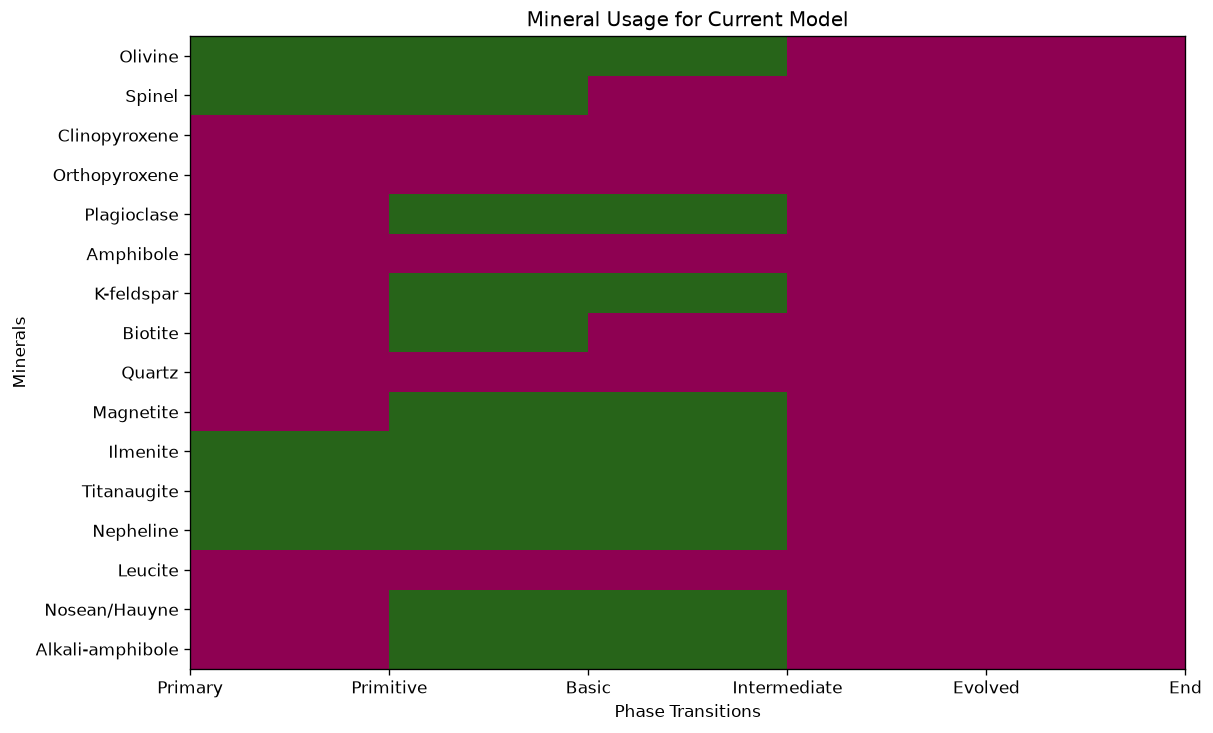

In [2]:
model.set_mineral_usage(
    primary__ilmenite=True,
    primary__titanaugite=True,
    primary__nepheline=True,
    __leucite=False,
    primitive__biotite=True,
    primitive__kfeldspar=True,
    basic__kfeldspar=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

In [3]:
# Specify the mineralogical compositions for minerals and phases (in wt.%)
model.set_mineralogies(
    primary__titanaugite =    [47.08,2.31,6.86,7.53,12.63,23.25,0.66,0],
    primitive__titanaugite =        [47.04,1.66,5.34,13.93,9.64,21.48,1.32,0],
    basic__titanaugite = [50.83,1.59,2.33,21.05,4.95,12.91,6.33,0],
)

Normalising composition for primary__titanaugite to 100 wt%. Original sum: 100.32
Normalising composition for primitive__titanaugite to 100 wt%. Original sum: 100.41
Normalising composition for basic__titanaugite to 100 wt%. Original sum: 99.99


**Optimisation**

In [4]:
# Run stages x
model.run(1)
model.run(2)
model.run(3)

> Optimisation completed with cost = 1.13 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.95 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 2.82 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


We can view the results for the entire model:

In [5]:
model.summary()

                        p-P        P-B        B-I     |     Total   
--------------------------------------------------------------------------------
            Type  |    Majors     Majors     Majors   |            
            Cost  |      1.13       0.95       2.82   |            
--------------------------------------------------------------------------------
               F  |        50         65         28   |       100    %
         Olivine  |    18.549     13.296      7.550   |    15.979    wt.%
          Spinel  |    16.178      6.892              |    11.818    wt.%
     Plagioclase  |                2.912      2.869   |     1.244    wt.%
      K-feldspar  |                0.361      2.770   |     0.289    wt.%
         Biotite  |                0.022              |     0.008    wt.%
       Magnetite  |                0.045      0.015   |     0.018    wt.%
        Ilmenite  |     3.288      5.824      3.284   |     4.231    wt.%
     Titanaugite  |    61.736     59.510    

**Visualising Results**

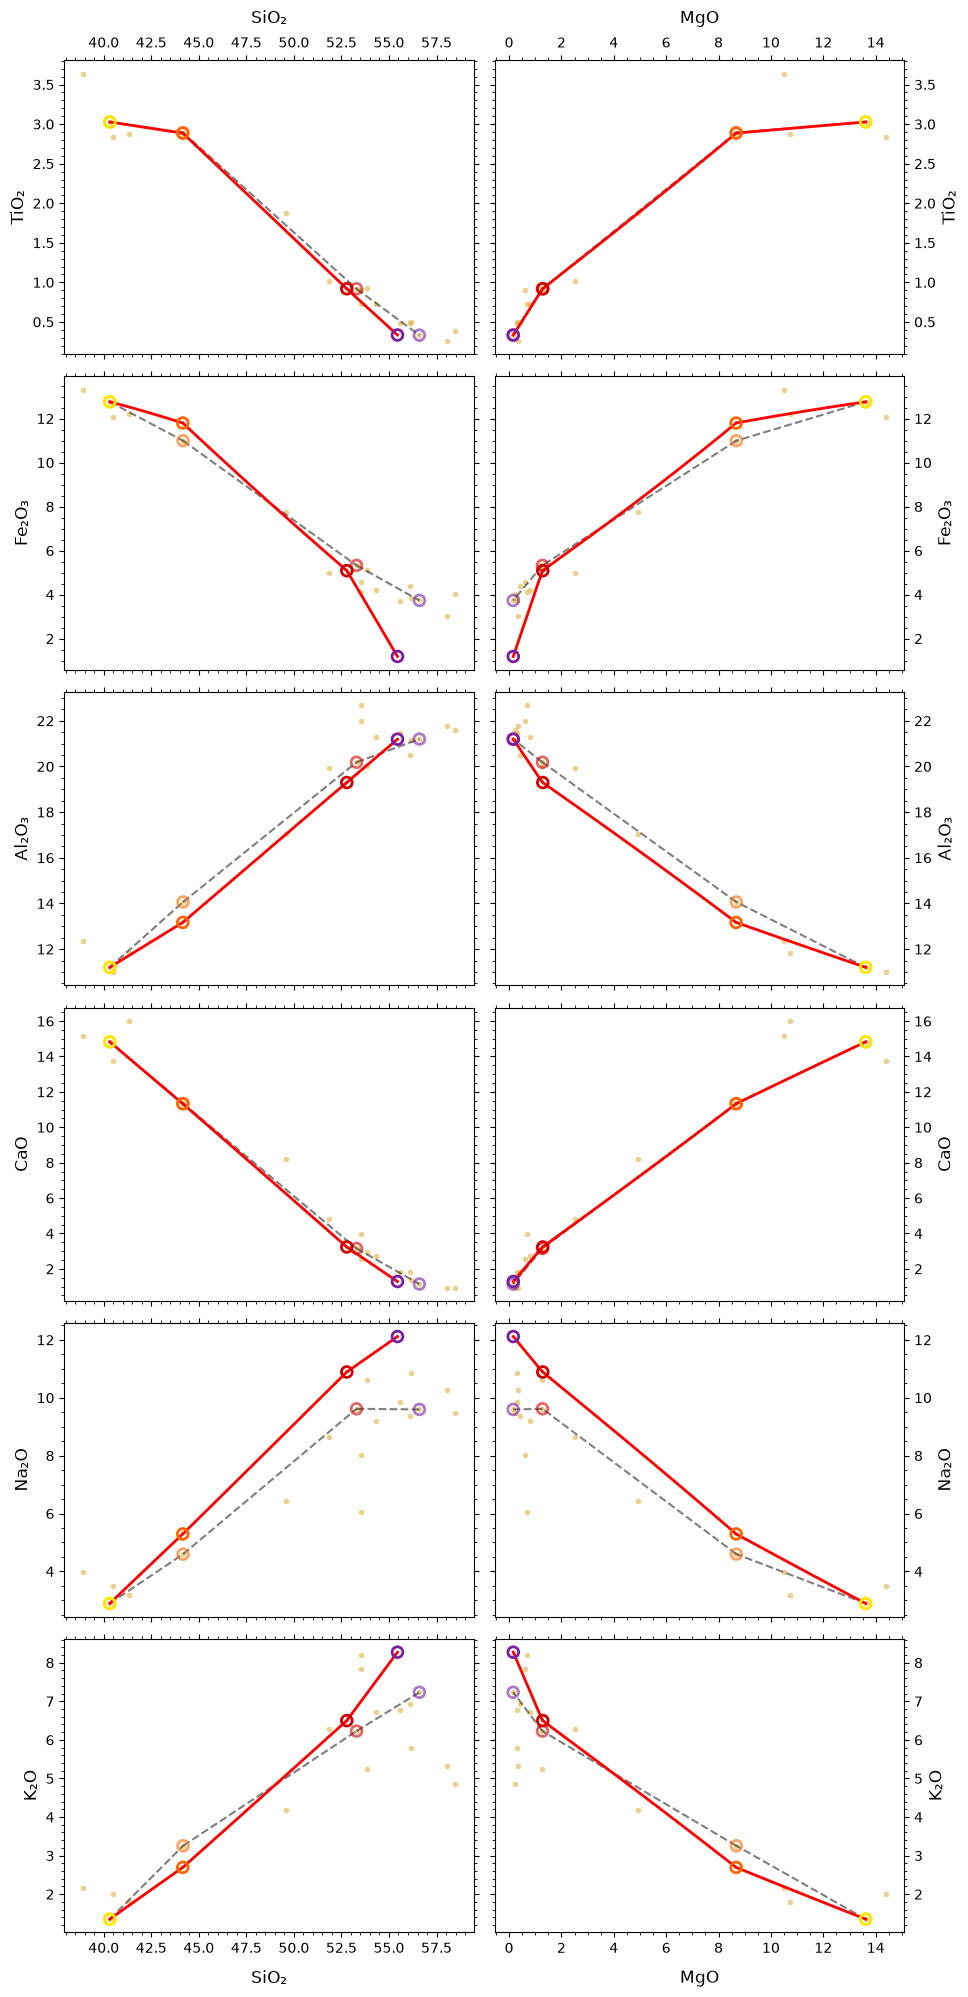

In [6]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots.png',
)

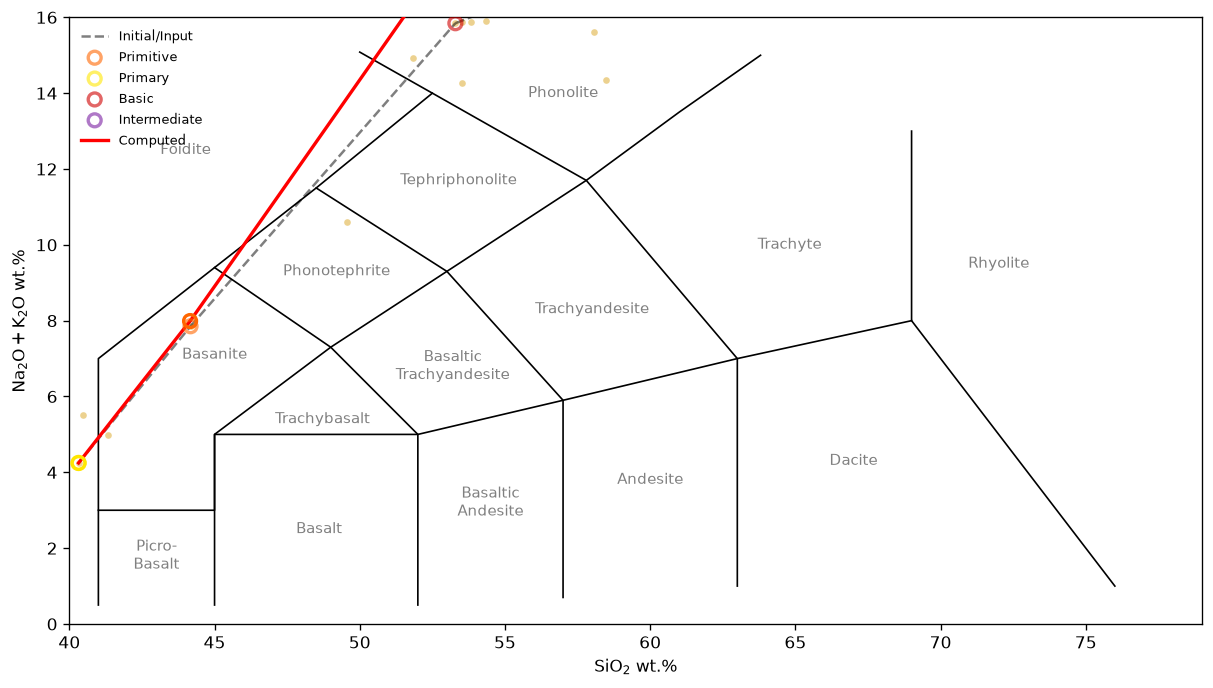

In [7]:
# Plot the TAS diagram and save to a file
from hades.visuals import tas
tas(
    model, 
    filename='./outputs/tas_diagram.png'
)

**Export Results**

In [8]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx


----

**Useful Commands**

Configuration Files

Having imported data and configured our desired parameters, we can save the configuration to a ``.hades`` file. This allows us to easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

In [9]:
model.save_config('./jbel_saghro.hades')

Successfully saved configuration to ./jbel_saghro.hades


To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [10]:
model = Obol.newModel()
model.load_config('./jbel_saghro.hades')

 To adjust the population size and maximum number of generations, you can use the following code before running the model

In [11]:
# model.optimising.max_iter = 500 # default
# model.optimising.pop_size = 50  # default